<a href="https://colab.research.google.com/github/wldnjs05/26-2-DIP-JIWONLEE/blob/main/notebook_2026/HW01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
!pip install nibabel

In [65]:
import nibabel as nib

- day015 및 day015를 day000에 registration한 파일을 각각 불러오기.
- day000을 포함하여 세 ct영상데이터의 동일한 단면을 display하여 비교하기.

In [66]:
ct_FU = nib.load('volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load('volume-covid19-A-0700_day015-reg_to_day000.nii.gz').get_fdata()

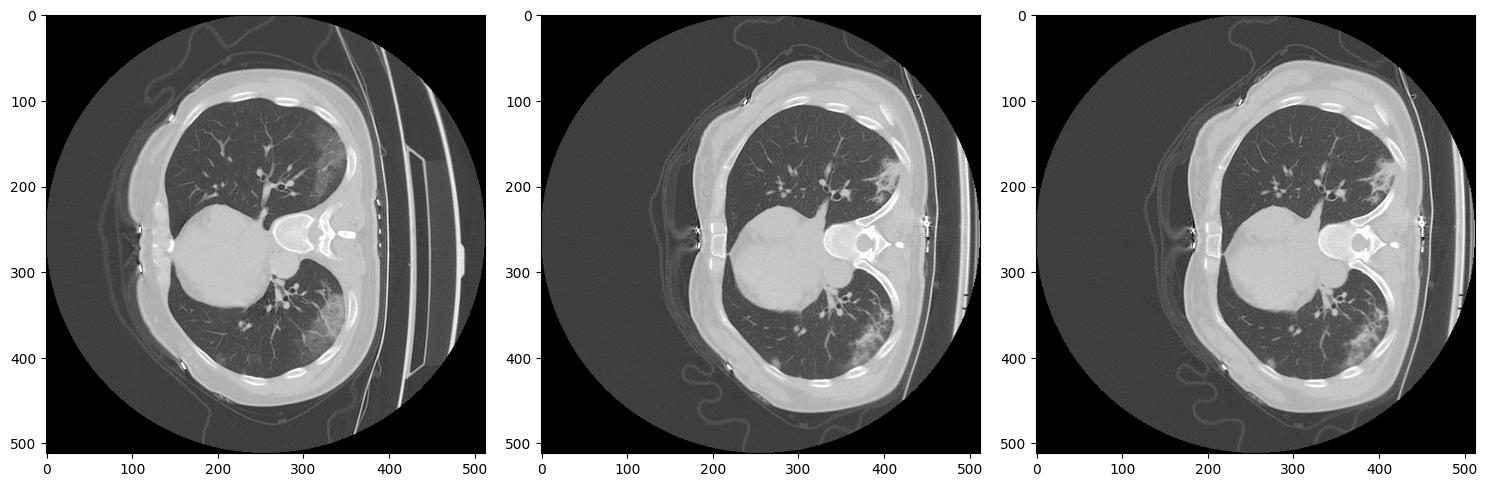

In [70]:
h = nib.load('volume-covid19-A-0700_day000.nii.gz')
ct_base = h.get_fdata()
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

In [56]:
import numpy as np
import matplotlib.pyplot as plt

In [27]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
import os
imgpath = '/content/drive/MyDrive/DIP4E'
#os.listdir(imgpath)


## Histogram Processing

In [29]:
f = plt.imread(imgpath+'/pollen-lowcontrast.tif')
print(f.shape,f.dtype)

(500, 500) uint8


- histogram equalization

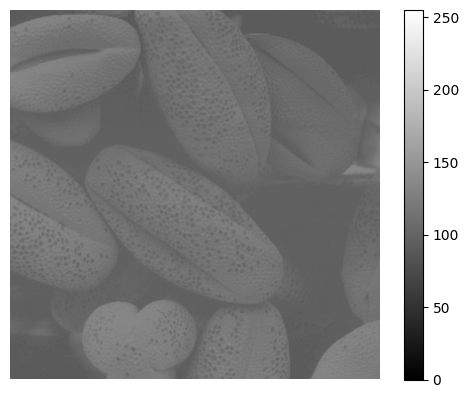

In [30]:
plt.imshow(f, cmap = 'gray', vmin=0, vmax=255)
plt.axis('off')
plt.colorbar()
plt.show()

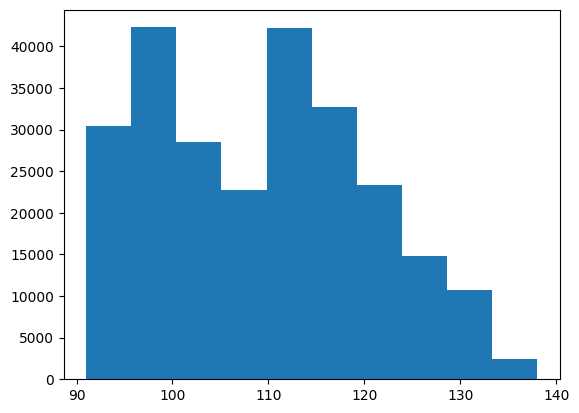

In [31]:
plt.hist(f.flatten())
plt.show()

In [32]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

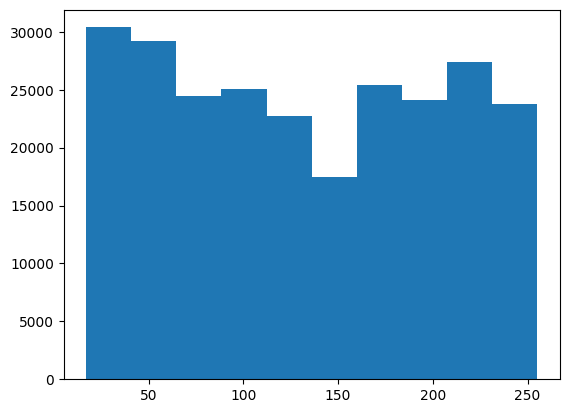

In [33]:
f_eq = histogram_equalization(f)
plt.hist(f_eq.flatten())
plt.show()

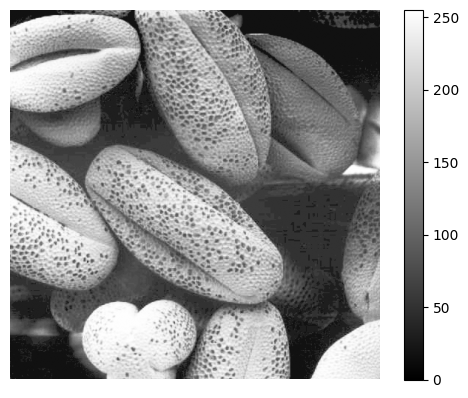

In [34]:
plt.imshow(f_eq, cmap = 'gray', vmin=0, vmax=255)
plt.axis('off')
plt.colorbar()
plt.show()

- local histogram equalization

In [35]:
f = plt.imread(imgpath+'/hidden-symbols.tif')
print(f.shape,f.dtype)

(256, 256) uint8


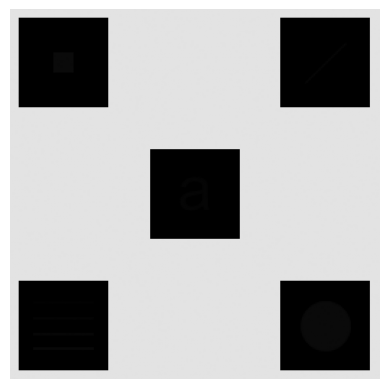

In [36]:
plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

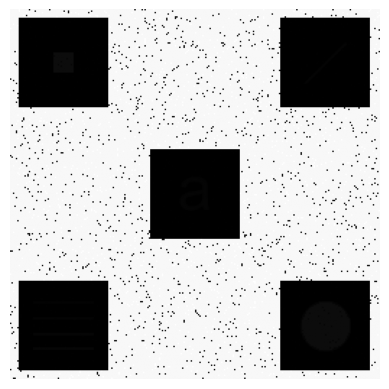

In [37]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

### Exercise 1.
- 아래의 예는 local histogram equalization을 수행한다.
- 적절한 neighborhood size N을 찾아서 숨겨진 기호들을 모두 확인해보자.
- plt.imshow의 vim, vmax를 수정하여서도 숨겨진 기호들을 확인할 수 있으나, 본 실습에서는 vmax=255로 고정하여 histogram processing을 통해 숨겨진 기호들을 확인하자.

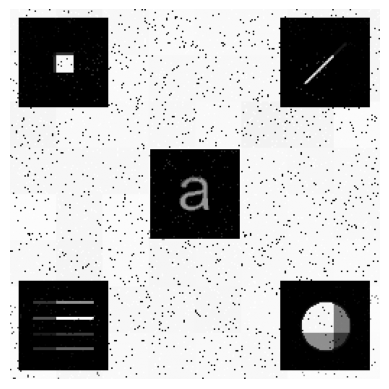

In [39]:
N = 32
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

### Exercise 2.
- 직접 찍은 사진을 grayscale image로 불러와서, kernel size를 3x3, 7x7, 15x15, 30x30 으로 늘려가며 box kernel을 정의하여 LPF를 진행한 결과를 출력하고 kernel size에 따른 연산시간의 차이를 확인하자.

In [45]:
f = io.imread('IMG_1012.jpg',as_gray=True)[::3, ::3]
print(f.shape,f.dtype)

(950, 1000) float64


In [46]:
import time

computation time =  0.05188941955566406  sec


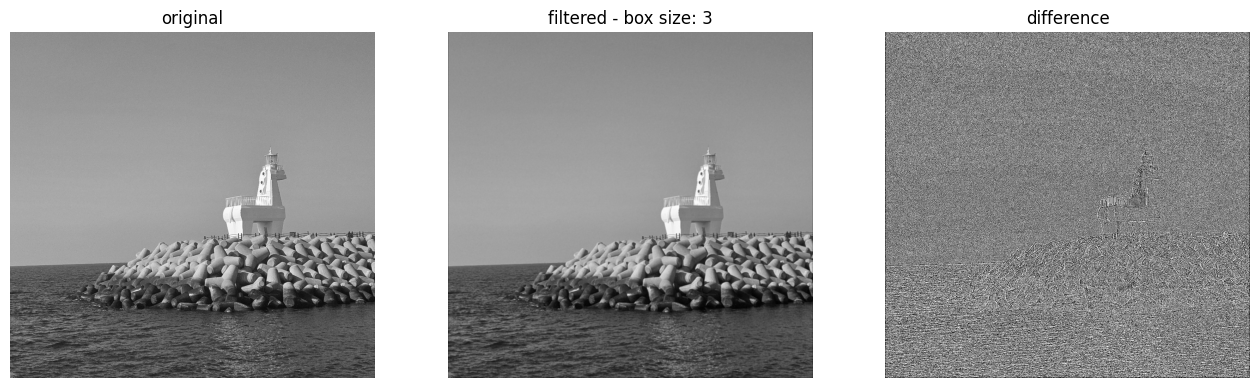

computation time =  0.16782236099243164  sec


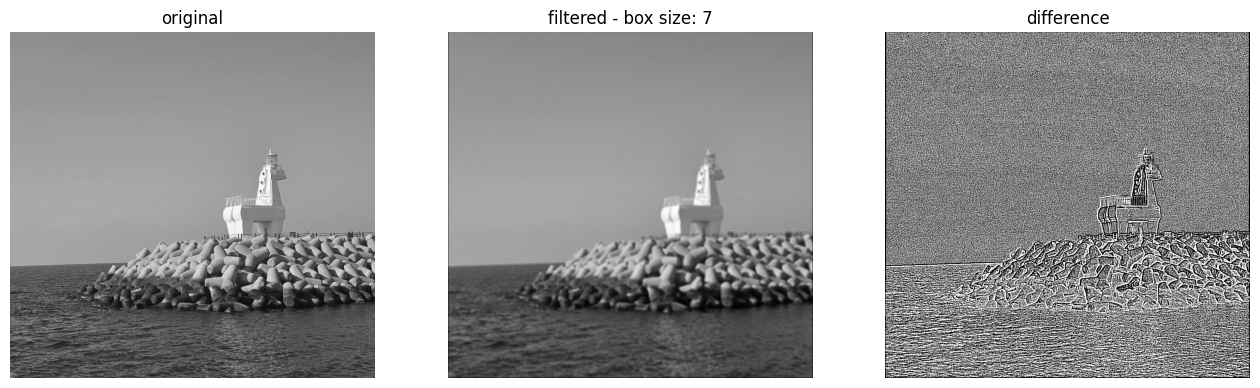

computation time =  0.5887272357940674  sec


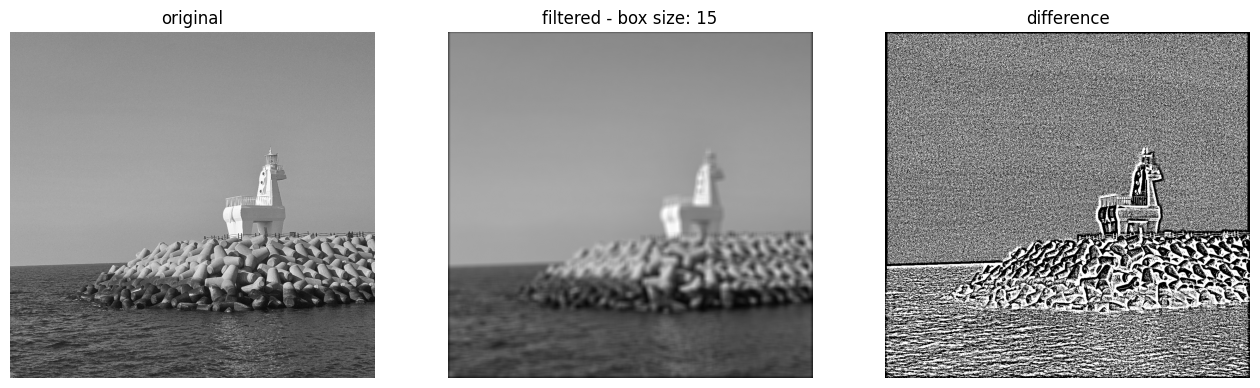

computation time =  2.1485230922698975  sec


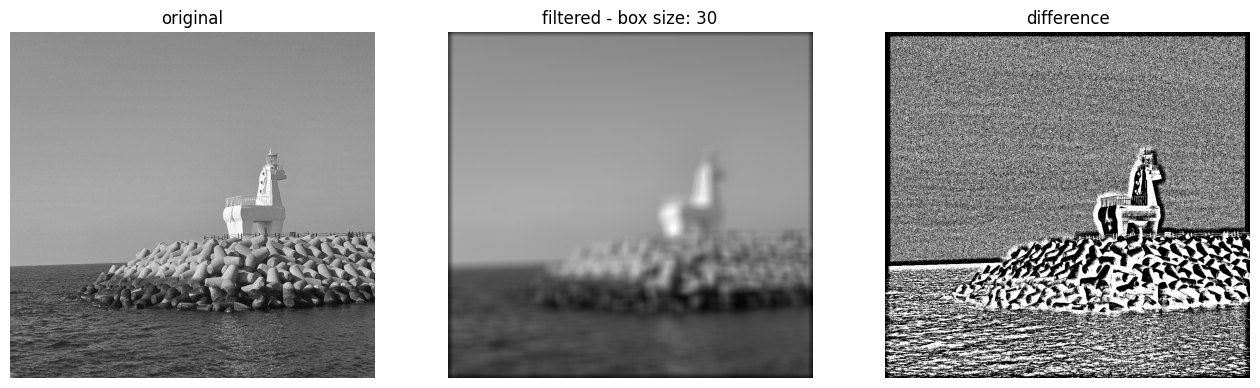

In [47]:
for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

### Exercise 3.
- highpass filtering의 결과를 활용하여 blurred image를 sharp하게 개선시켜 보자.
- 자신만의 blurred image를 가져와서, Laplacian kernel을 통한 highpass filtering을 진행하고 이를 이용하여 원본영상의 sharpness를 증대시켜보자.
- w 및 c를 적절하게 변화시켜 가면서 결과를 확인하자.

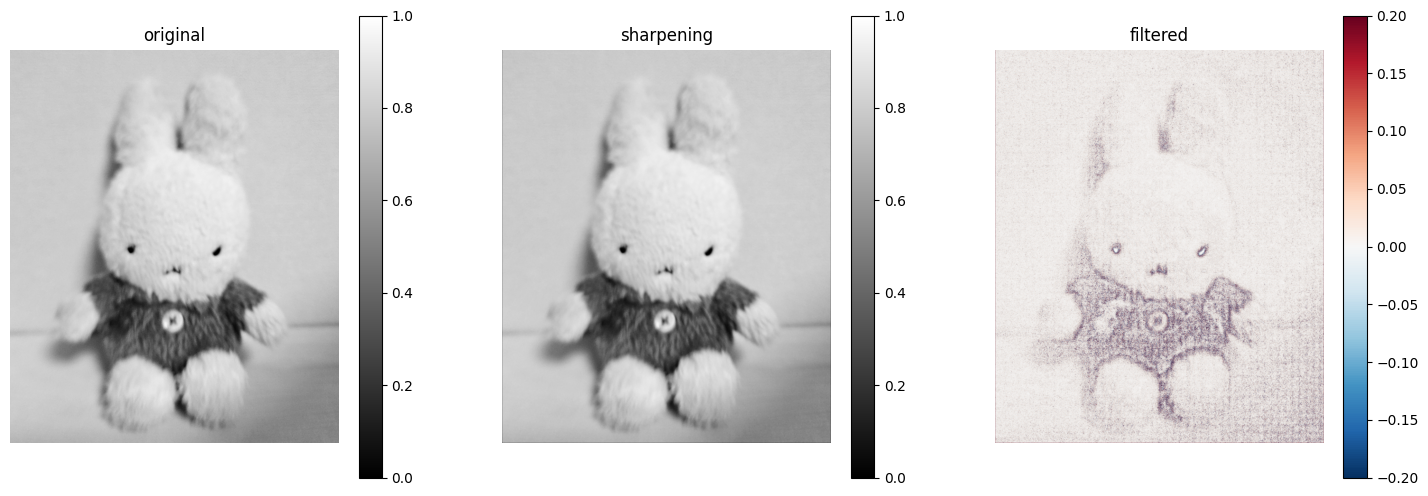

In [81]:
f = io.imread('IMG_1012(2).jpg', as_gray=True)

w = np.array([[-1,-1,-1],[-1,8.,-1],[-1,-1,-1]])
y = signal.convolve2d(f,w,mode='same')
c = 0.3
g = f - c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray',vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray',vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.2, vmax=0.2)
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()

## Sobel (1st order diff.)

In [74]:
sobel1 = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
sobel2 = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
print(sobel1)
print(sobel2)

[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


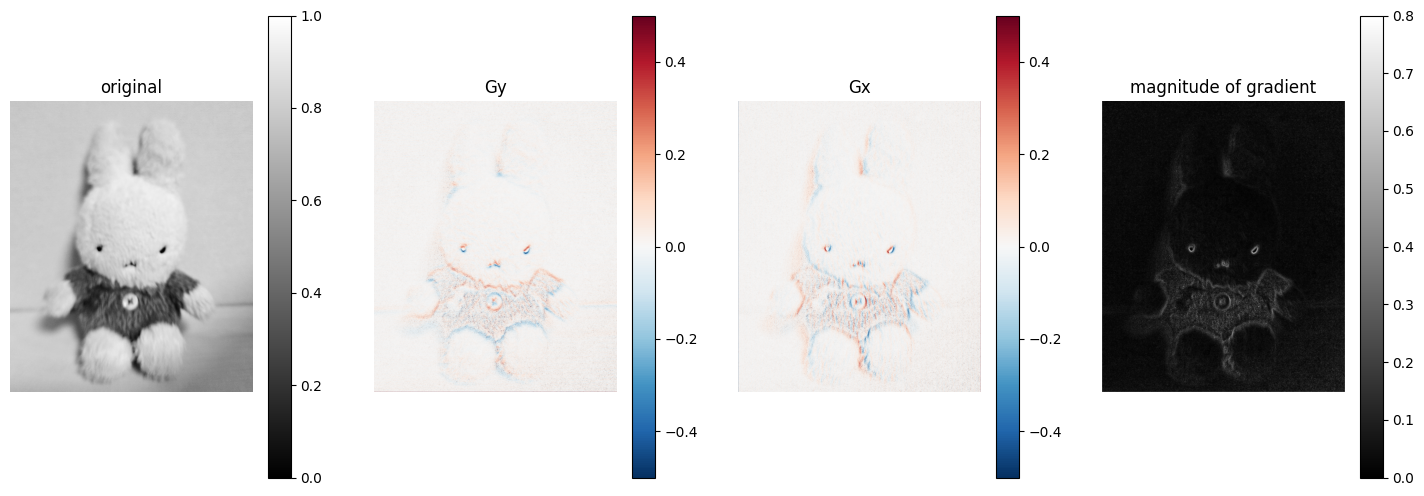

In [83]:
g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(141)
plt.imshow(f,cmap='gray',vmin=0, vmax=1)
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(142)
plt.imshow(g1,cmap='RdBu_r',vmin=-0.5, vmax=0.5)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(143)
plt.imshow(g2,cmap='RdBu_r',vmin=-0.5, vmax=0.5)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.subplot(144)
plt.imshow(G,cmap='gray',vmin=0, vmax=0.8)
plt.colorbar()
plt.axis('off')
plt.title('magnitude of gradient')
plt.show()

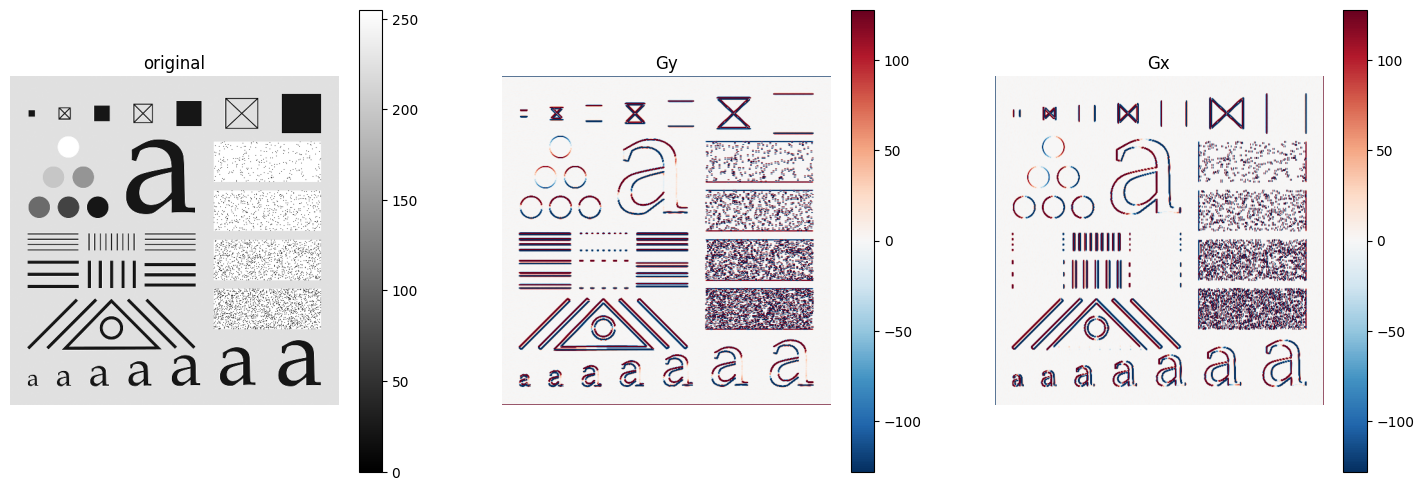

In [76]:
f = plt.imread(os.path.join(imgpath,'testpattern512.tif'))

g1 = signal.convolve2d(f,sobel1,mode='same')
g2 = signal.convolve2d(f,sobel2,mode='same')
G = np.sqrt(g1**2+g2**2)

plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g1,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gy')
plt.subplot(133)
plt.imshow(g2,cmap='RdBu_r',vmin=-128,vmax=128)
plt.colorbar()
plt.axis('off')
plt.title('Gx')
plt.show()


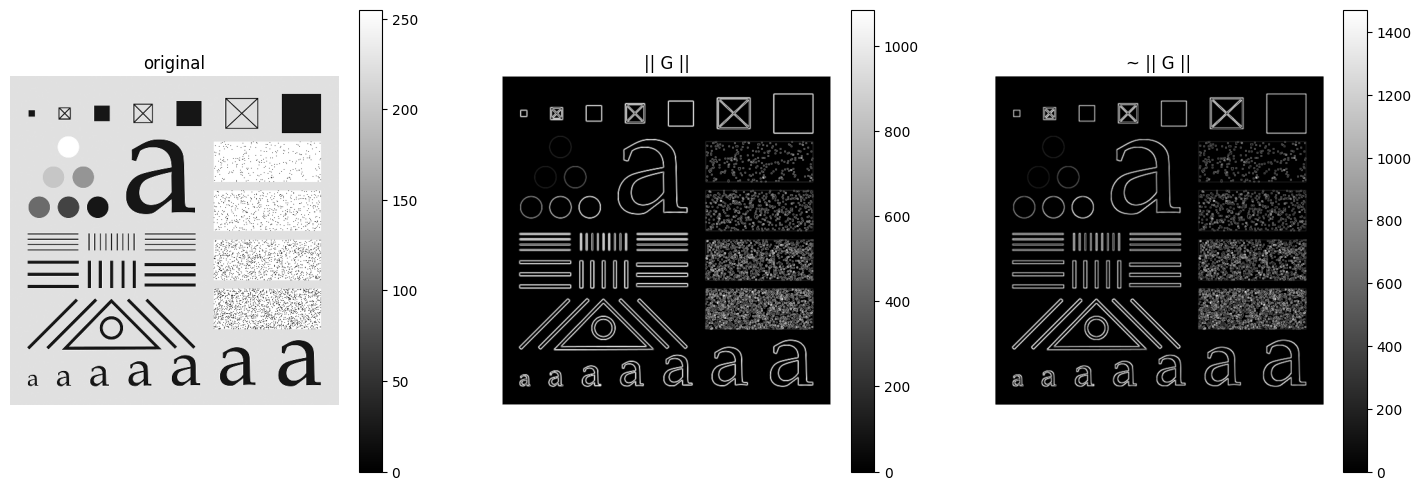

In [77]:
G_ = np.abs(g1) + np.abs(g2)
plt.figure(figsize=(18,6))

plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')

plt.subplot(132)
plt.imshow(G,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('|| G ||')

plt.subplot(133)
plt.imshow(G_,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('~ || G ||')

plt.show()
